In [1]:
from ET_pylib.setup import *
setup_notebook()

# Shock `visual` analysis

In [2]:
GEO   = "disaggEA"
print("kernekraft-id'er:", use_geography(GEO))   # skal vise idNUC_DK1 og idNUC_DK2

yr    = 2040
ids   = NUCLEAR_IDS_BY_GEO[GEO]
RUN   = "disaggEA_2040_kf25om"           # 2040 med brintfiks
SHOCK = "shock_nuc_2040.pkl"
# RUN   = "disaggEA_2025_2050"      # DREAMs 2025-2050 uden brintfiks

kernekraft-id'er: {'idNUC_DK1': 2035, 'idNUC_DK2': 2035}


In [3]:
baseline_output, shock_output = load_run(RUN, SHOCK)
nuc, cut = nuc_wind_swap(baseline_output, shock_output, yr=yr, nuc_ids=ids)
id2Pt, id2EA = shock_output["id2Pt"].vals, shock_output["id2EA"].vals   # nuclear-ids findes kun i shock-db

Kapacitetsbytte, 2040 (GW)
────────────────────────────────────────────────────────────
                                   basis      stød         Δ
────────────────────────────────────────────────────────────
  Kernekraft DK1                    0,00      0,65     +0,65
  Kernekraft DK2                    0,00      0,35     +0,35
  Havvind DK1                       4,50      3,22     -1,28
  Havvind DK2                       1,79      1,25     -0,55
────────────────────────────────────────────────────────────
  Kernekraft i alt                                     +1,00
  Havvind i alt                                        -1,82
  Havvind fjernet pr. GW kernekraft                     1,82
────────────────────────────────────────────────────────────


In [4]:
ctx_el     = build_el_balance_data(baseline_output, shock_output, years=yr)
ctx_el_agg = build_el_balance_data_country(baseline_output, shock_output, years=yr)
shares     = build_supply_shares(ctx_el, aggregates=c_aggs_countries)

## `Plotting en masse`

### `1. Price-sorted decomposition`

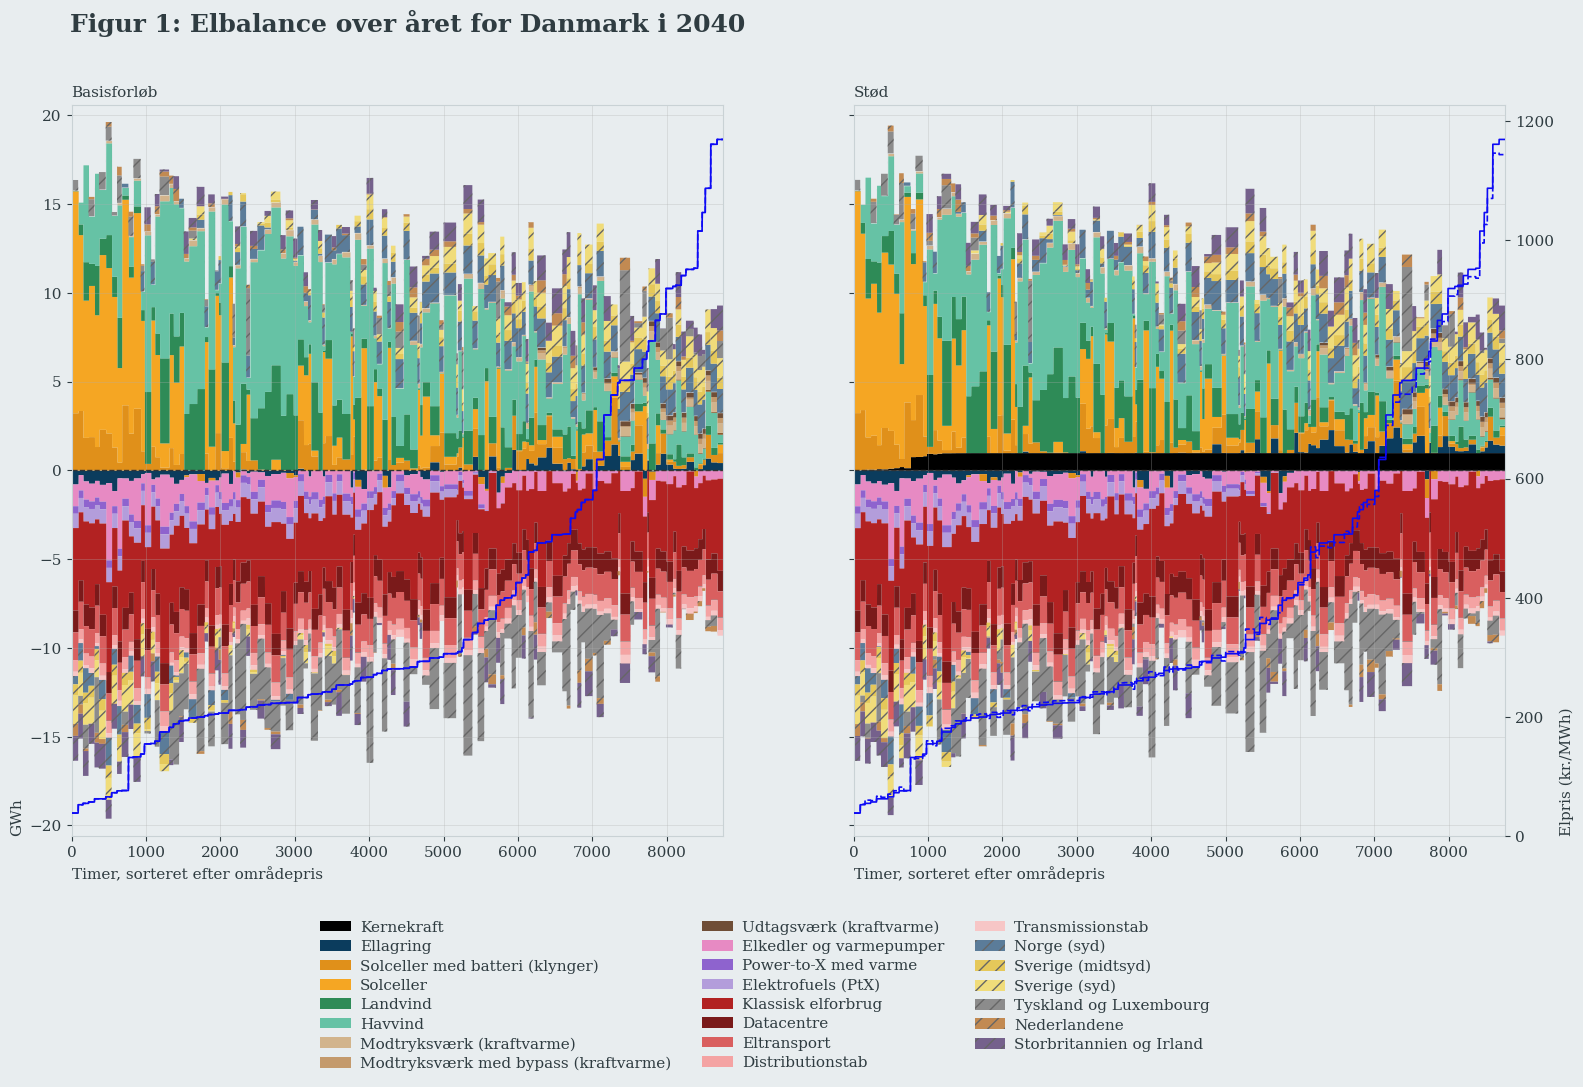

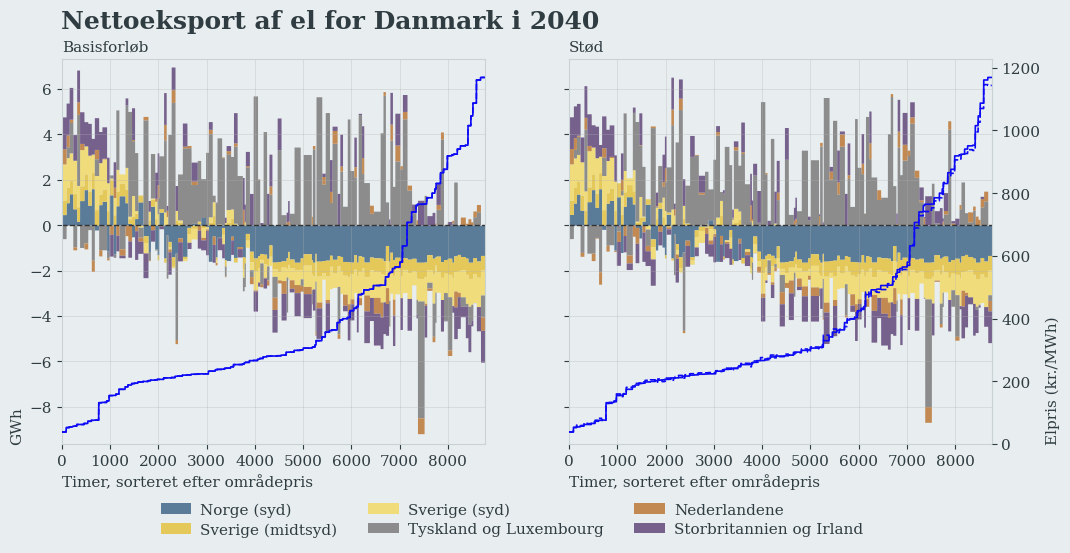

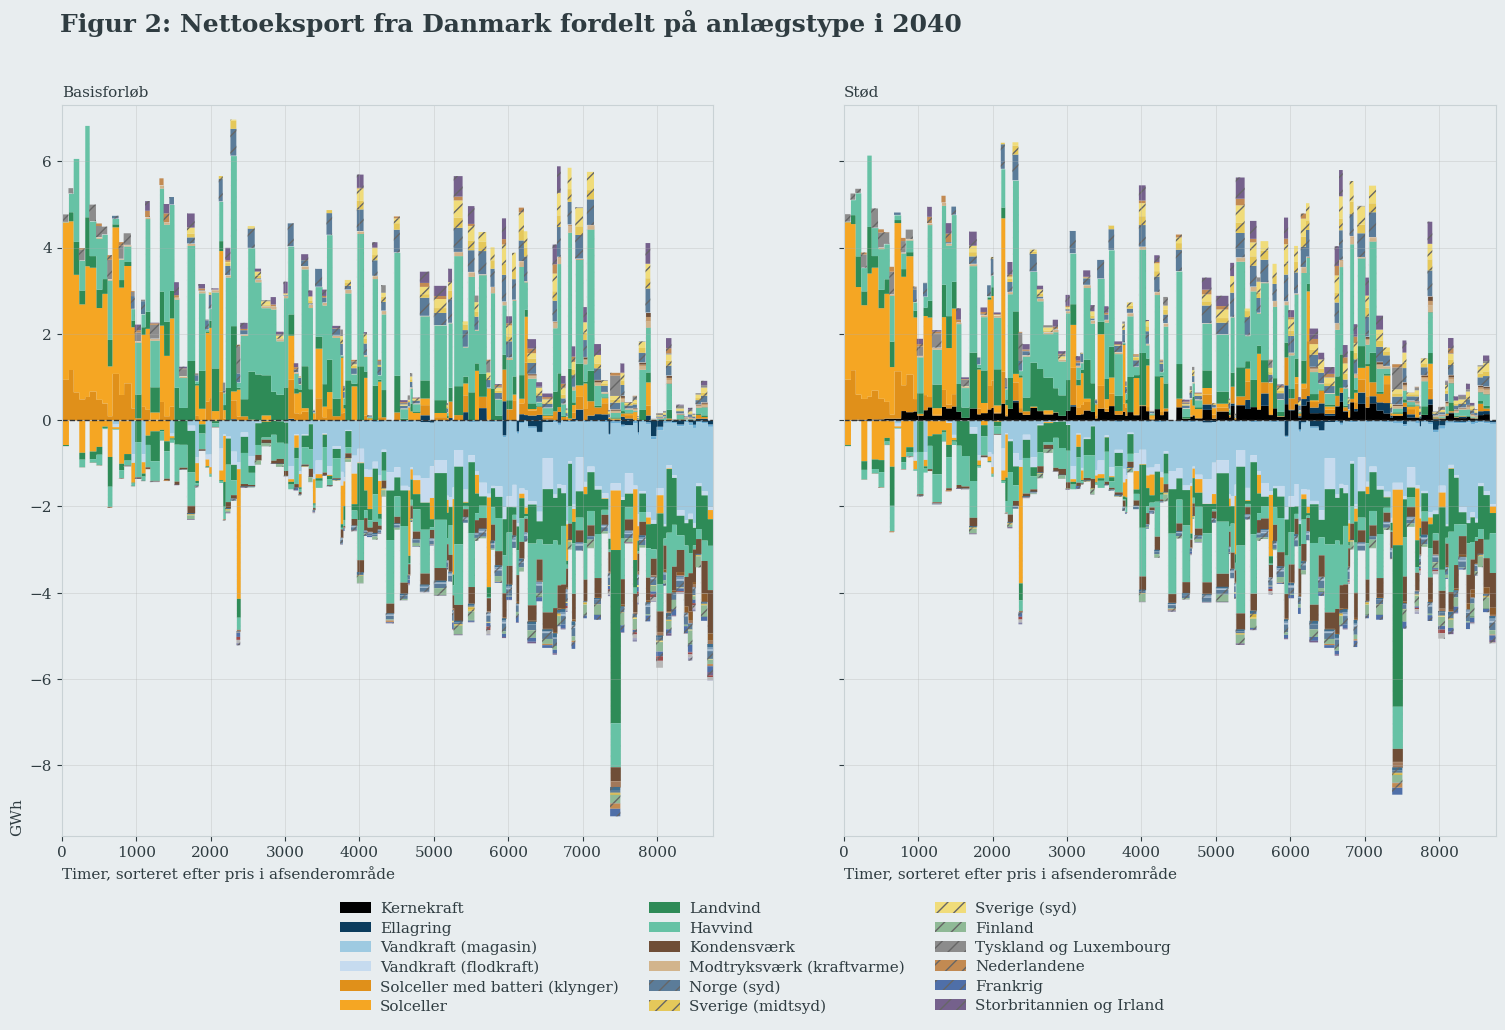

[(<Figure size 1850x950 with 2 Axes>,
  (<Axes: title={'left': 'Basisforløb'}, xlabel='Timer, sorteret efter pris i afsenderområde', ylabel='GWh'>,
   <Axes: title={'left': 'Stød'}, xlabel='Timer, sorteret efter pris i afsenderområde'>))]

In [14]:
plot_energy_balance_el(ctx_el_agg, 'DK', years=yr, figsize=(18.5, 9.5), 
                       legend_y=-0.15, legend_min_twh=0.2)
plot_net_export(ctx_el_agg, 'DK', years=yr)
plot_net_export_by_pt_agg(
    ctx_el_agg, "DK", ["SE", "NO", "DELU", "GBNIIE", "NL"],
    share_dict=shares, partner_map=c_aggs_countries, years=yr, legend_min_twh=0.2,
    figsize=(18.5, 9.5), legend_y=-0.09,
)

### `2. Prices`

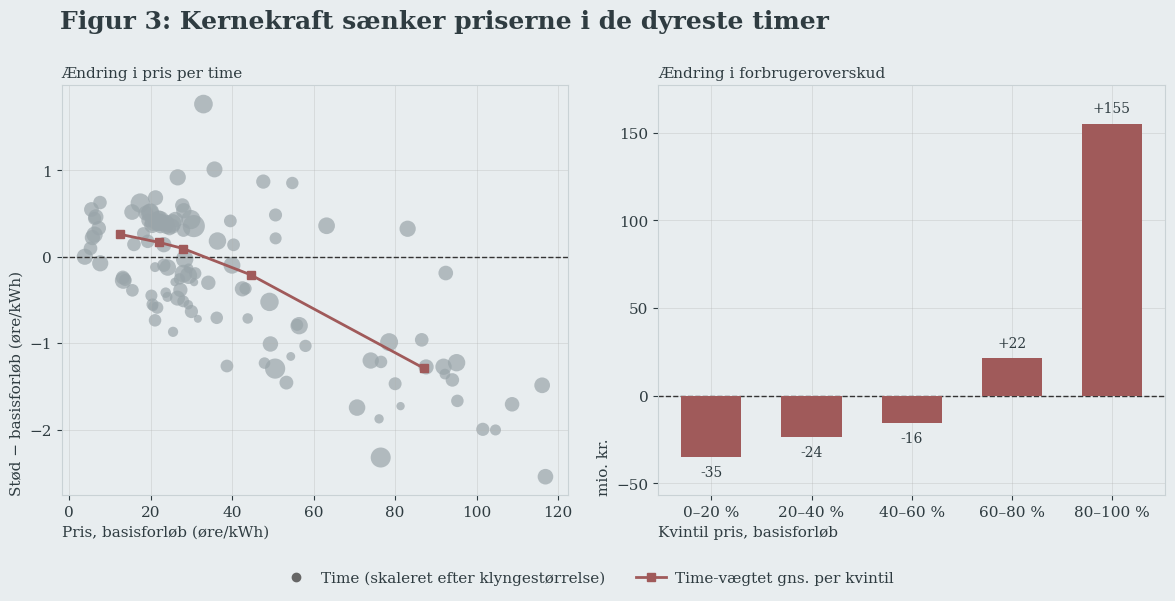

(<Figure size 1200x600 with 2 Axes>,
 (<Axes: title={'left': 'Ændring i pris per time'}, xlabel='Pris, basisforløb (øre/kWh)', ylabel='Stød − basisforløb (øre/kWh)'>,
  <Axes: title={'left': 'Ændring i forbrugeroverskud'}, xlabel='Kvintil pris, basisforløb', ylabel='mio. kr.'>))

In [6]:
plot_price_change_and_cs(ctx_el, baseline_output, shock_output, "DK", year=yr, figsize=(12, 6))

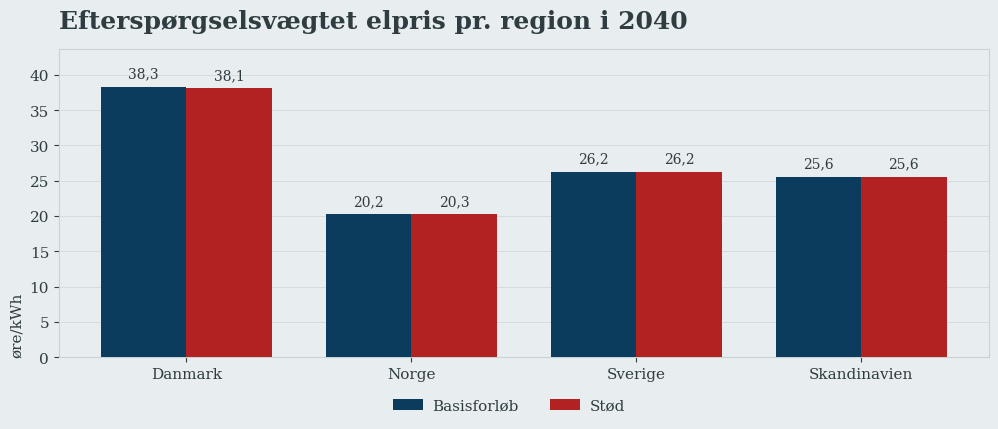

mean {'DK': np.float64(-0.161), 'NO': np.float64(0.048), 'SE': np.float64(0.012), 'Scandi': np.float64(0.003)}
std {'DK': np.float64(-0.594), 'NO': np.float64(0.008), 'SE': np.float64(-0.024), 'Scandi': np.float64(-0.078)}


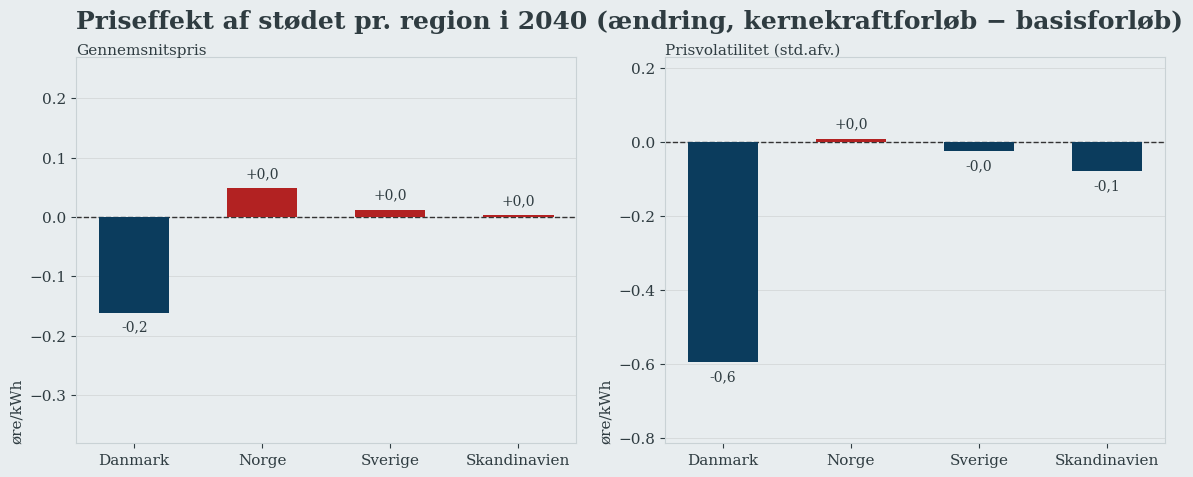

In [7]:
fig, ax   = plot_price_levels(ctx_el, years=yr)
fig, axes = plot_price_delta(ctx_el, years=yr, stats=("mean", "std"), verbose=True)

### `3. Trade`

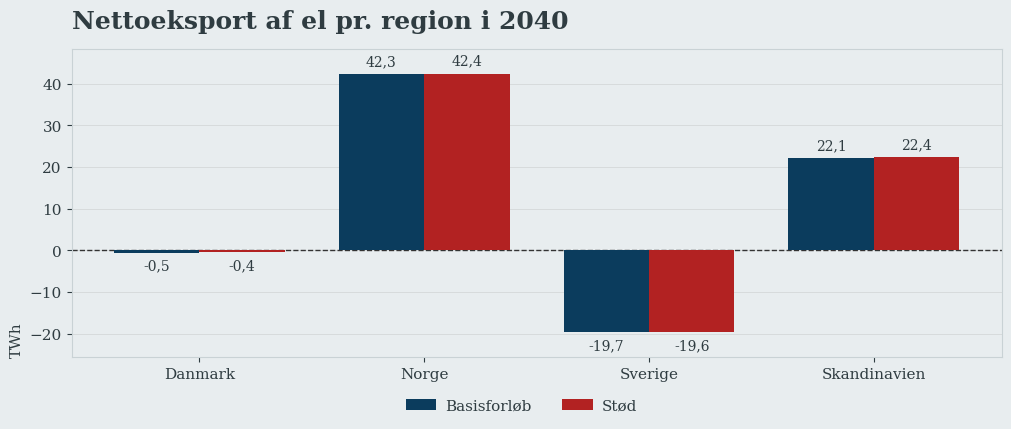

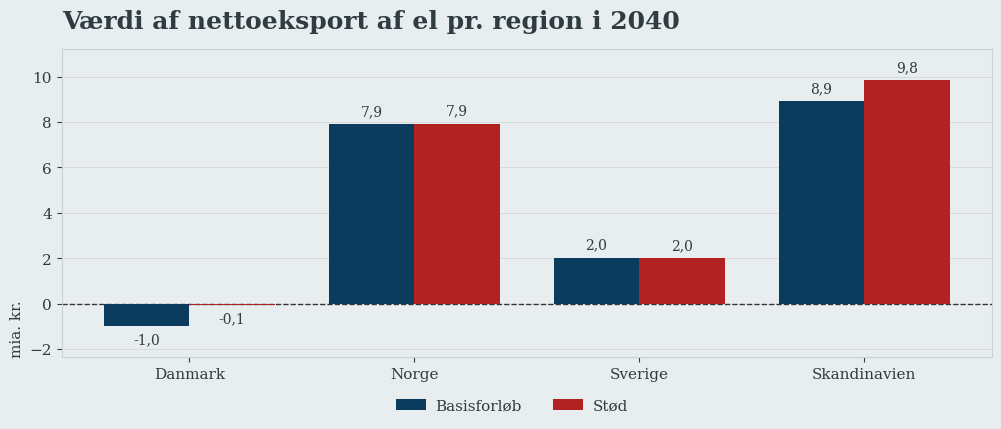

(<Figure size 1200x400 with 1 Axes>, <Axes: ylabel='mia. kr.'>)

In [8]:
plot_trade_levels(ctx_el, years=yr)
plot_trade_levels(ctx_el, years=yr, value=True)

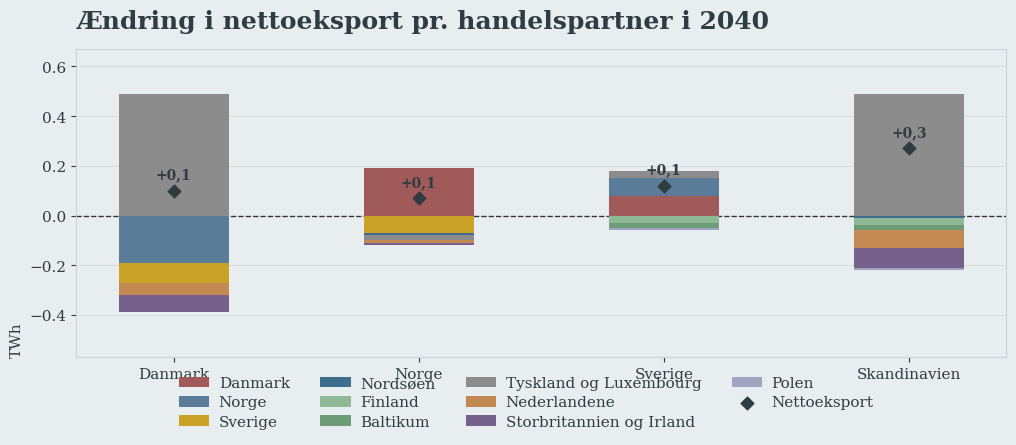

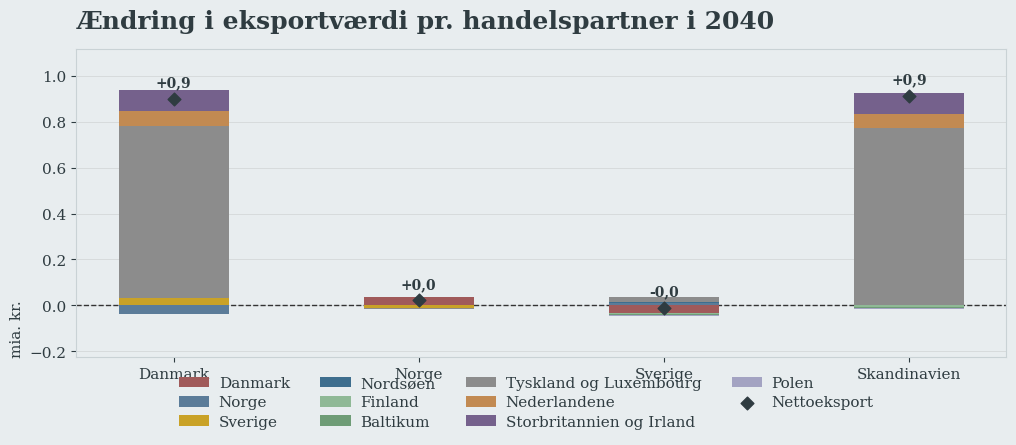

(<Figure size 1200x400 with 1 Axes>, <Axes: ylabel='mia. kr.'>)

In [9]:
plot_trade_delta_by_partner(ctx_el, years=yr)
plot_trade_delta_by_partner(ctx_el, years=yr, value=True)

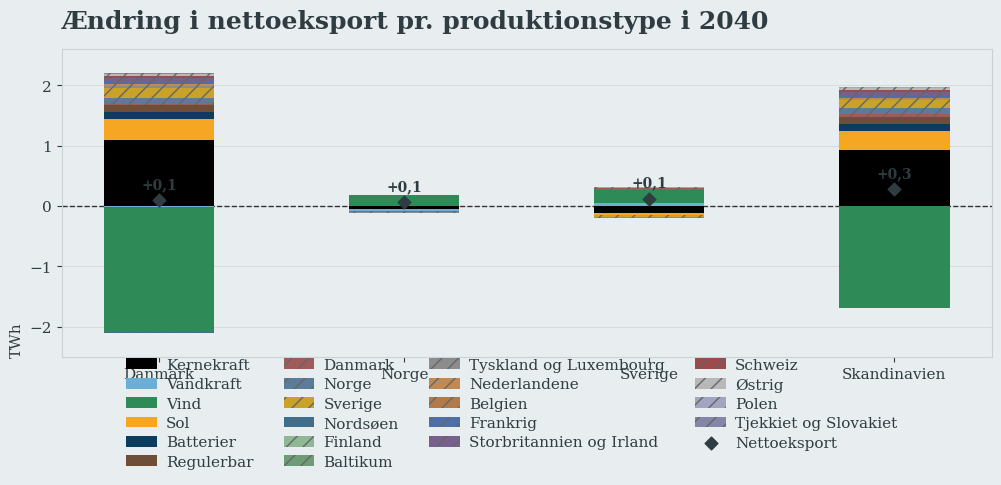

(<Figure size 1200x400 with 1 Axes>, <Axes: ylabel='TWh'>)

In [10]:
plot_nx_delta_by_pt(ctx_el, shares, years=yr)

### `4. Value factor`

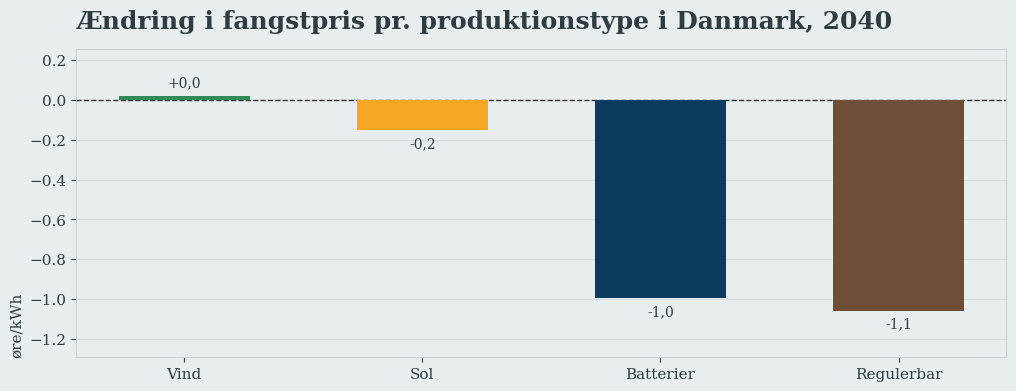

(<Figure size 1200x400 with 1 Axes>, <Axes: ylabel='øre/kWh'>)

In [11]:
plot_capture_delta_by_pt(ctx_el, years=yr)

### `5. Welfare proxy`

    0–20 %  20–40 %  40–60 %  60–80 %  80–100 %    total
DK  -30.37  -30.074   -13.64   23.242   153.245  102.403


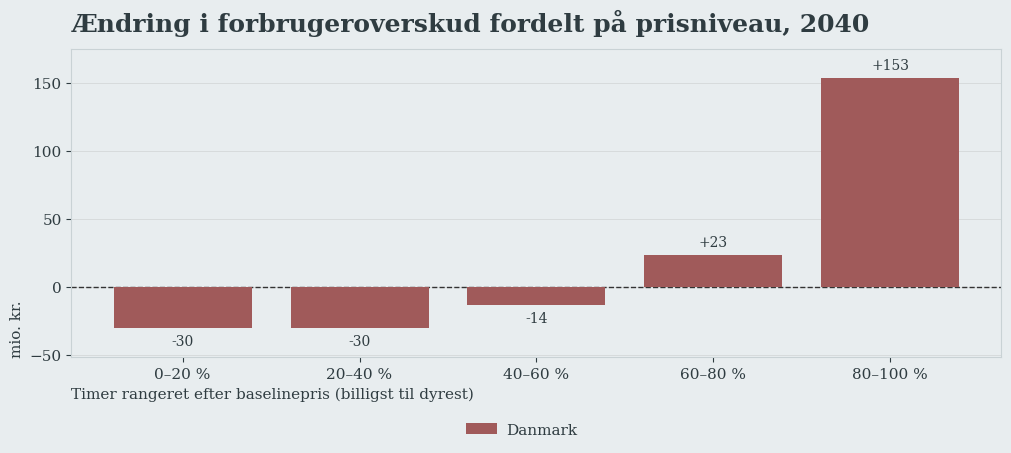

(<Figure size 1200x400 with 1 Axes>,
 <Axes: xlabel='Timer rangeret efter baselinepris (billigst til dyrest)', ylabel='mio. kr.'>)

In [12]:
plot_cs_by_price_bin(baseline_output, shock_output, regions=["DK"], year=yr, verbose=True)

### `6. Producer quantities`

In [13]:
plot_generation_stack(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, bar_width=0.38)
# plot_profit_stack(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, bar_width=0.38)

NameError: name 'id2Pt' is not defined

In [ ]:
plot_generation_delta(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, regions=["DK"])
plot_profit_delta(baseline_output, shock_output, id2Pt=id2Pt, id2EA=id2EA, year=yr, regions=["DK"])

NameError: name 'id2Pt' is not defined